<a href="https://colab.research.google.com/github/fri17da/Data_Mining_SEMS4/blob/main/Tugas_1_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Iris.csv', sep=';')
print(df.head())

  Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0                      1,5.1,3.5,1.4,0.2,Iris-setosa              
1                      2,4.9,3.0,1.4,0.2,Iris-setosa              
2                      3,4.7,3.2,1.3,0.2,Iris-setosa              
3                      4,4.6,3.1,1.5,0.2,Iris-setosa              
4                      5,5.0,3.6,1.4,0.2,Iris-setosa              


In [ ]:
print(df.columns)

Index(['Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species'], dtype='object')


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Iris.csv', sep=';')
print(df.head())

  Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0                      1,5.1,3.5,1.4,0.2,Iris-setosa              
1                      2,4.9,3.0,1.4,0.2,Iris-setosa              
2                      3,4.7,3.2,1.3,0.2,Iris-setosa              
3                      4,4.6,3.1,1.5,0.2,Iris-setosa              
4                      5,5.0,3.6,1.4,0.2,Iris-setosa              


In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Iris.csv', sep=';')
print(df.head())

  Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0                      1,5.1,3.5,1.4,0.2,Iris-setosa              
1                      2,4.9,3.0,1.4,0.2,Iris-setosa              
2                      3,4.7,3.2,1.3,0.2,Iris-setosa              
3                      4,4.6,3.1,1.5,0.2,Iris-setosa              
4                      5,5.0,3.6,1.4,0.2,Iris-setosa              


In [ ]:
X = df.iloc[:, 1:5]

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Iris.csv', sep=',')
features = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
X = df[features]

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
inertia = []
K = range(1, 10)

for k in K:

    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

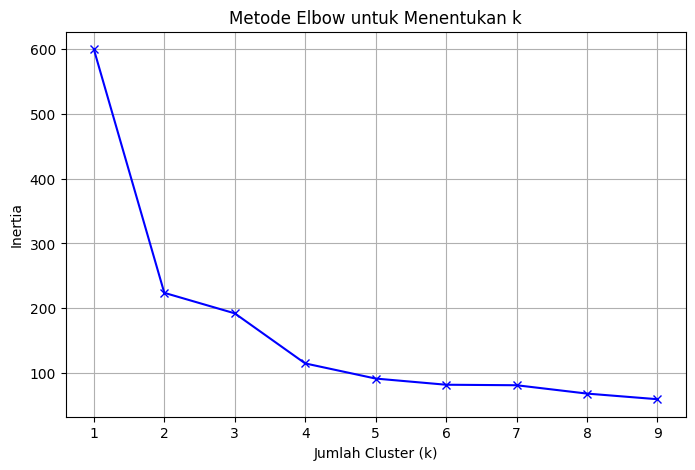

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(K, inertia, 'bx-')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Metode Elbow untuk Menentukan k')
plt.grid(True)
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)
print(df.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   Cluster  
0        1  
1        2  
2        2  
3        2  
4        1  


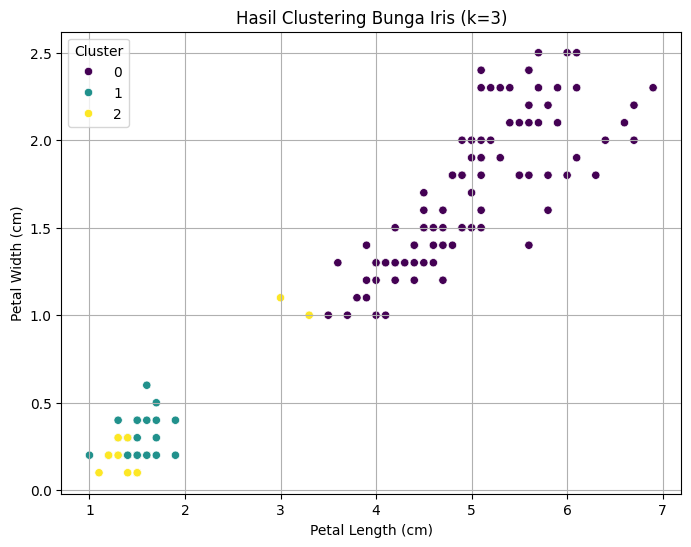

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['PetalLengthCm'], y=df['PetalWidthCm'], hue=df['Cluster'], palette='viridis')

plt.title('Hasil Clustering Bunga Iris (k=3)')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.grid(True)
plt.show()

In [ ]:
silhouette_avg = silhouette_score(X_scaled, df['Cluster'])
print(f"Silhouette Score (k=3): {silhouette_avg:.3f}")

Silhouette Score (k=3): 0.479


In [ ]:
print(f"Inertia Akhir (k=3): {kmeans.inertia_:.3f}")

Inertia Akhir (k=3): 192.037


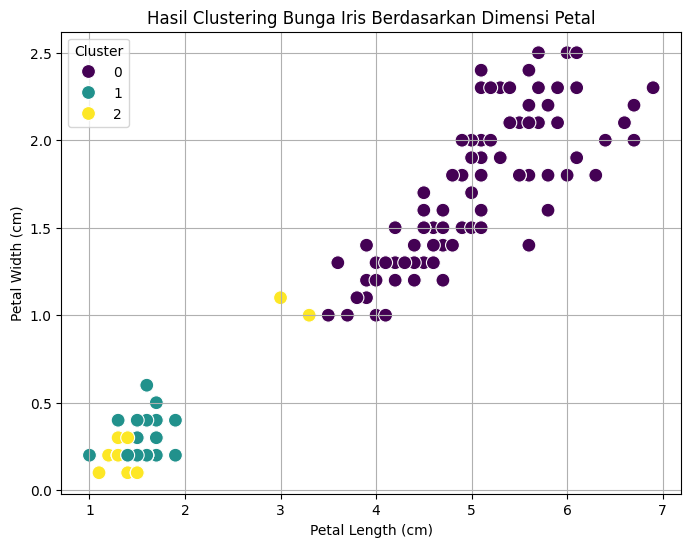

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    x=df['PetalLengthCm'],
    y=df['PetalWidthCm'],
    hue=df['Cluster'],
    palette='viridis',
    s=100
)

plt.title('Hasil Clustering Bunga Iris Berdasarkan Dimensi Petal')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()